# 7. Tutorial 7

**Course:** High Switching Frequency Power Converters

## 7.1 Skin depth and Dowell's factor

Copper at $100~^\circ\mathrm{C}$, $\rho = 2.26\cdot10^{-8}~\Omega\mathrm{m}$.

7.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt, scipy.optimize) and create the functions
- `get_delta(f, rho)`: skin depth $\delta = \sqrt{\rho/(\pi f \mu_0)}$,
- `get_FR(phi, M)`: Dowell's factor $F_\mathrm{R} = \varphi\left[G_1 + \frac{2}{3}(M^2-1)(G_1 - 2G_2)\right]$.

Print $\delta$ at 1, 2, 6.78 and $13.56~\mathrm{MHz}$ and $F_\mathrm{R}$ of four layers of $35~\mu\mathrm{m}$ at $2~\mathrm{MHz}$. Plot $F_\mathrm{R}$ versus $\varphi$ in the range [$0.1 \ldots 10$] for $M = 1, 2, 4, 6$ (log axes).

7.1.2 Find the thickness that minimises $F_\mathrm{R}/\varphi$ (winding resistance for a fixed winding width) numerically for $M = 1 \ldots 10$ and compare it with $\varphi_\mathrm{opt} \approx (15/(5M^2-1))^{1/4}$.


f =  1.00 MHz: delta =  75.7 um
f =  2.00 MHz: delta =  53.5 um
f =  6.78 MHz: delta =  29.1 um
f = 13.56 MHz: delta =  20.5 um
35 um at 2 MHz: phi = 0.654, FR(M=4) = 1.319


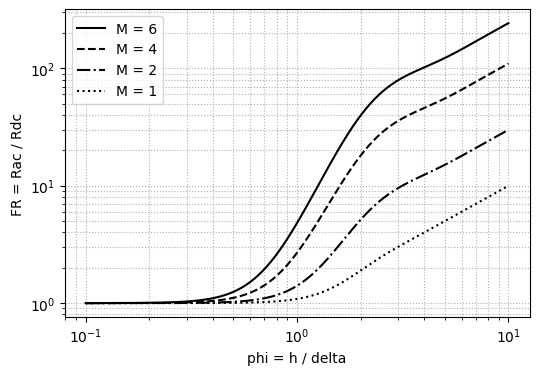

In [1]:
# Subtask 7.1.1 Import necessary modules and create the functions
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

mu0 = 4e-7 * np.pi
rho_100 = 2.26e-8


def get_delta(f, rho=rho_100):
    """Skin depth in m."""
    return np.sqrt(rho / (np.pi * f * mu0))


def get_FR(phi, M):
    """Dowell's AC resistance factor of a winding portion with M layers (sinusoidal current)."""
    G1 = (np.sinh(2 * phi) + np.sin(2 * phi)) / (np.cosh(2 * phi) - np.cos(2 * phi))
    G2 = (np.sinh(phi) * np.cos(phi) + np.cosh(phi) * np.sin(phi)) / (np.cosh(2 * phi) - np.cos(2 * phi))
    return phi * (G1 + 2 / 3 * (M**2 - 1) * (G1 - 2 * G2))


for f in (1e6, 2e6, 6.78e6, 13.56e6):
    print(f"f = {f/1e6:5.2f} MHz: delta = {get_delta(f)*1e6:5.1f} um")
phi = 35e-6 / get_delta(2e6)
print(f"35 um at 2 MHz: phi = {phi:.3f}, FR(M=4) = {get_FR(phi, 4):.3f}")

if __name__ == "__main__":
    p = np.logspace(-1, 1, 300)
    plt.figure(figsize=(6, 4))
    for M, ls in ((6, '-'), (4, '--'), (2, '-.'), (1, ':')):
        plt.loglog(p, get_FR(p, M), 'k' + ls, label=f'M = {M}')
    plt.xlabel('phi = h / delta'); plt.ylabel('FR = Rac / Rdc')
    plt.grid(True, which='both', ls=':'); plt.legend(); plt.show()


In [2]:
# Subtask 7.1.2 Optimum layer thickness
print(" M  phi_opt  approx  FR(opt)")
for M in range(1, 11):
    res = optimize.minimize_scalar(lambda q: get_FR(q, M) / q, bounds=(0.05, 5), method='bounded')
    approx = (15 / (5 * M**2 - 1))**0.25
    print(f"{M:2d}  {res.x:6.3f}  {approx:6.3f}  {get_FR(res.x, M):6.3f}")
print(f"M = 1: pi/2 = {np.pi/2:.3f}; at 2 MHz the optimum thickness for M = 4 is {0.663*get_delta(2e6)*1e6:.1f} um")


 M  phi_opt  approx  FR(opt)
 1   1.571   1.392   1.441
 2   0.961   0.943   1.349
 3   0.770   0.764   1.340
 4   0.663   0.660   1.337
 5   0.591   0.590   1.336
 6   0.539   0.538   1.335
 7   0.499   0.498   1.334
 8   0.466   0.466   1.334
 9   0.439   0.439   1.334
10   0.417   0.416   1.334
M = 1: pi/2 = 1.571; at 2 MHz the optimum thickness for M = 4 is 35.5 um


### 7.1.2 Solution

At $100~^\circ\mathrm{C}$: $\delta = 75.7$, $53.5$, $29.1$ and $20.5~\mu\mathrm{m}$. Four layers of $35~\mu\mathrm{m}$ at $2~\mathrm{MHz}$: $\varphi = 0.654$, $F_\mathrm{R} = 1.32$. The approximation of the optimum is within 2 % for $M \geq 2$ and $F_\mathrm{R}(\varphi_\mathrm{opt}) \approx 4/3$; for $M = 1$ the optimum is at $\varphi = \pi/2$ with $F_\mathrm{R} = 1.44$ (the approximation does not apply). For $M = 4$ at $2~\mathrm{MHz}$ the optimum is $35~\mu\mathrm{m}$, i.e. 1-oz copper.


## 7.2 Winding of a ZVS buck inductor

$I_\mathrm{dc} = 8.33~\mathrm{A}$, triangular ripple $\Delta i = 20~\mathrm{A}$ peak to peak at $2~\mathrm{MHz}$ with $D = 0.25$; $R_\mathrm{dc} = 4~\mathrm{m\Omega}$ for $35~\mu\mathrm{m}$ copper, proportional to $1/h$.

7.2.1 Create the function `get_triangle_harmonics(di, D, n_max)` that returns the harmonic orders and rms values of a triangular wave ($\hat{\imath}_n = \Delta i\,|\sin(n\pi D)|/(\pi^2 n^2 D(1-D))$). Check that the harmonics add up to $\Delta i/(2\sqrt{3})$.

7.2.2 Create the function `get_P_winding(h, M, ...)` and compute the loss for $35$ and $70~\mu\mathrm{m}$ with $M = 2$. Plot the loss versus $h$ in the range [$10 \ldots 250~\mu\mathrm{m}$] for $M = 1, 2, 4$ and print the optimum thicknesses, with and without the DC part.


In [3]:
# Subtask 7.2.1 Harmonics of the triangular ripple
def get_triangle_harmonics(di, D, n_max=400):
    """Harmonic orders and rms values of a triangular wave with peak-to-peak value di and rise fraction D."""
    n = np.arange(1, n_max + 1)
    amp = di * np.abs(np.sin(n * np.pi * D)) / (np.pi**2 * n**2 * D * (1 - D))
    return n, amp / np.sqrt(2)


I_dc, di, D, f_sw = 100 / 12, 20.0, 0.25, 2e6
n, I_n = get_triangle_harmonics(di, D)
print("rms of the first harmonics:", np.round(I_n[:5], 3))
print(f"sum of harmonics: {np.sqrt(np.sum(I_n**2)):.4f} A, di/(2 sqrt 3) = {di/(2*np.sqrt(3)):.4f} A")


rms of the first harmonics: [5.404 1.911 0.6   0.    0.216]
sum of harmonics: 5.7735 A, di/(2 sqrt 3) = 5.7735 A


h = 35 um, M = 2: P = 0.427 W
h = 70 um, M = 2: P = 0.301 W
M = 1: optimum 250 um (ripple only: 82 um), P(opt)/P(35 um) = 0.32


M = 2: optimum 69 um (ripple only: 47 um), P(opt)/P(35 um) = 0.71


M = 4: optimum 44 um (ripple only: 32 um), P(opt)/P(35 um) = 0.94


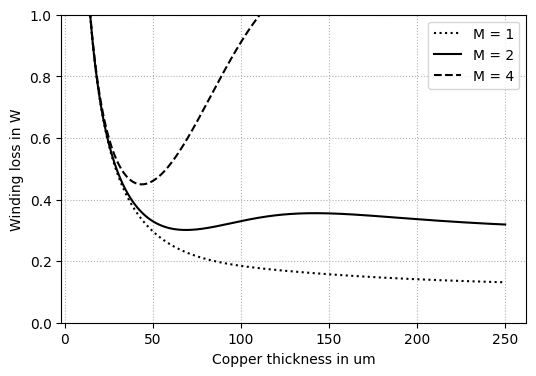

In [4]:
# Subtask 7.2.2 Winding loss versus copper thickness
R_dc35 = 4e-3


def get_P_winding(h, M, with_dc=True):
    """Winding loss in W for copper thickness h (m) and M layers."""
    phi1 = h / get_delta(f_sw)
    R_dc = R_dc35 * 35e-6 / h
    P_ac = R_dc * np.sum(I_n**2 * get_FR(phi1 * np.sqrt(n), M))
    return P_ac + (R_dc * I_dc**2 if with_dc else 0.0)


for h in (35e-6, 70e-6):
    print(f"h = {h*1e6:.0f} um, M = 2: P = {get_P_winding(h, 2):.3f} W")
h_sweep = np.linspace(10e-6, 250e-6, 481)
P_sweep = {}
for M in (1, 2, 4):
    P_sweep[M] = np.array([get_P_winding(h, M) for h in h_sweep])
    P_ac = np.array([get_P_winding(h, M, with_dc=False) for h in h_sweep])
    print(f"M = {M}: optimum {h_sweep[np.argmin(P_sweep[M])]*1e6:.0f} um (ripple only: {h_sweep[np.argmin(P_ac)]*1e6:.0f} um), "
          f"P(opt)/P(35 um) = {P_sweep[M].min()/get_P_winding(35e-6, M):.2f}")

if __name__ == "__main__":
    plt.figure(figsize=(6, 4))
    for M, ls in ((1, ':'), (2, '-'), (4, '--')):
        plt.plot(h_sweep * 1e6, P_sweep[M], 'k' + ls, label=f'M = {M}')
    plt.xlabel('Copper thickness in um'); plt.ylabel('Winding loss in W'); plt.ylim(0, 1.0)
    plt.grid(True, ls=':'); plt.legend(); plt.show()


### 7.2.2 Solution

The harmonics reproduce the rms value of the ripple ($5.77~\mathrm{A}$). With two layers: $0.43~\mathrm{W}$ for $35~\mu\mathrm{m}$ and $0.30~\mathrm{W}$ for $70~\mu\mathrm{m}$. The optimum lies at about $69~\mu\mathrm{m}$ with the DC part and at about $47~\mu\mathrm{m}$ for the ripple alone: two thirds of $I_\mathrm{rms}^2$ is DC and profits from thick copper. With four layers the optimum is about $44~\mu\mathrm{m}$; with one layer the loss keeps falling up to $250~\mu\mathrm{m}$.


## 7.3 Layer stack of a planar transformer

Copper $t = 35~\mu\mathrm{m}$, insulation $s = 0.1~\mathrm{mm}$ ($\varepsilon_\mathrm{r} = 4.4$), $\mathrm{MLT} = 40~\mathrm{mm}$, $h_\mathrm{w} = 8~\mathrm{mm}$. Each layer carries $\pm I_\mathrm{p}$ ampere-turns (+ for primary, - for secondary layers).

7.3.1 Create the functions
- `get_mmf(stack)`: MMF at the layer boundaries in units of $I_\mathrm{p}$ for a stack given as a string such as `'PPPPSSSS'`,
- `get_leakage(stack, t, s, MLT, h_w)`: leakage inductance referred to the primary (1-D energy method),
- `get_C_ps(stack, ...)`: capacitance between primary and secondary (all adjacent P-S interfaces in parallel).

Evaluate `'PPPPSSSS'`, `'PSPSSPSP'` and `'PSPSPSPS'` and plot their MMF.

7.3.2 Plot the high-frequency reduction of the leakage inductance (Hurley and Wölfle, Eq. 6.82)
$$\frac{L_\mathrm{lk,ac}}{L_\mathrm{lk}} = \frac{3}{2p^2\Delta}\left[\frac{\sinh 2\Delta - \sin 2\Delta}{\cosh 2\Delta - \cos 2\Delta} + \frac{2(p^2-1)}{3}\,\frac{\sinh\Delta + \sin\Delta}{\cosh\Delta + \cos\Delta}\right]$$
versus $\Delta = h/\delta$ in the range [$0.1 \ldots 10$] for $p = 1, 2, 4$ layers.


PPPPSSSS: MMF [0 1 2 3 4 3 2 1 0], L_lk =  37.0 nH, 1 P-S interfaces, C_ps =  125 pF
PSPSSPSP: MMF [ 0  1  0  1  0 -1  0 -1  0], L_lk =   3.1 nH, 6 P-S interfaces, C_ps =  748 pF
PSPSPSPS: MMF [0 1 0 1 0 1 0 1 0], L_lk =   3.1 nH, 7 P-S interfaces, C_ps =  873 pF


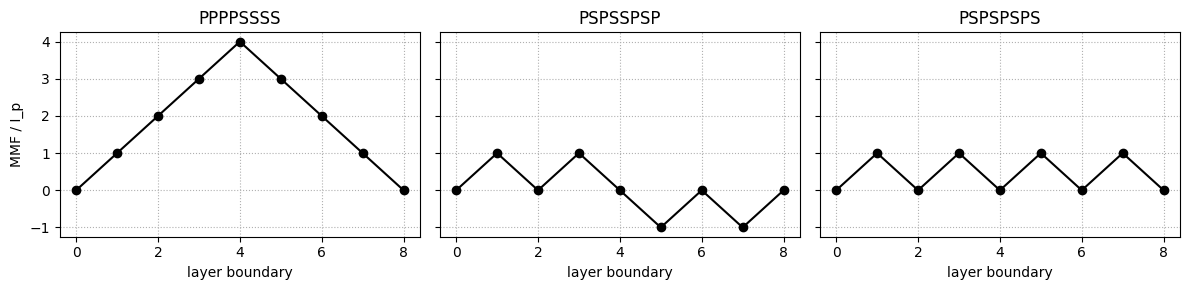

In [5]:
# Subtask 7.3.1 Leakage and capacitance of layer stacks
t, s, MLT, h_w, eps_r = 35e-6, 0.1e-3, 40e-3, 8e-3, 4.4
eps0 = 8.854e-12


def get_mmf(stack):
    """MMF at the layer boundaries in units of I_p (P: +1, S: -1 ampere-turn unit per layer)."""
    F = [0.0]
    for layer in stack:
        F.append(F[-1] + (1.0 if layer == 'P' else -1.0))
    return np.array(F)


def get_leakage(stack, t, s, MLT, h_w):
    """Leakage inductance referred to the primary (1-D energy method), H."""
    F = get_mmf(stack)
    integral = 0.0
    for k in range(len(stack)):
        F1, F2 = F[k], F[k + 1]
        integral += t * (F1**2 + F1 * F2 + F2**2) / 3
        if k < len(stack) - 1:
            integral += s * F2**2
    return mu0 * MLT / h_w * integral


def get_C_ps(stack, s, MLT, h_w, eps_r):
    """Capacitance between primary and secondary: adjacent P-S interfaces in parallel, F."""
    n_if = sum(1 for a, b in zip(stack[:-1], stack[1:]) if a != b)
    return n_if, n_if * eps0 * eps_r * MLT * h_w / s


for stack in ('PPPPSSSS', 'PSPSSPSP', 'PSPSPSPS'):
    n_if, C = get_C_ps(stack, s, MLT, h_w, eps_r)
    print(f"{stack}: MMF {get_mmf(stack).astype(int)}, L_lk = {get_leakage(stack, t, s, MLT, h_w)*1e9:5.1f} nH, "
          f"{n_if} P-S interfaces, C_ps = {C*1e12:4.0f} pF")

if __name__ == "__main__":
    fig, ax = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
    for a, stack in zip(ax, ('PPPPSSSS', 'PSPSSPSP', 'PSPSPSPS')):
        a.plot(np.arange(len(stack) + 1), get_mmf(stack), 'k-o')
        a.set_title(stack); a.set_xlabel('layer boundary'); a.grid(True, ls=':')
    ax[0].set_ylabel('MMF / I_p'); plt.tight_layout(); plt.show()


p = 1: L_ac/L = 0.976 at Delta = 1, 0.752 at Delta = 2
p = 2: L_ac/L = 0.970 at Delta = 1, 0.696 at Delta = 2
p = 4: L_ac/L = 0.968 at Delta = 1, 0.682 at Delta = 2


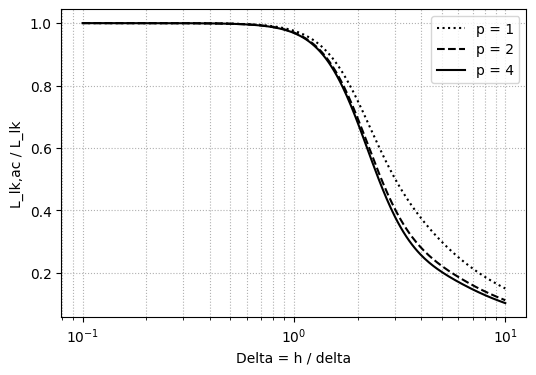

In [6]:
# Subtask 7.3.2 Leakage inductance at high frequency (Hurley and Woelfle, Eq. 6.82)
def get_L_ratio(Delta, p):
    a = (np.sinh(2 * Delta) - np.sin(2 * Delta)) / (np.cosh(2 * Delta) - np.cos(2 * Delta))
    b = (np.sinh(Delta) + np.sin(Delta)) / (np.cosh(Delta) + np.cos(Delta))
    return 3 / (2 * p**2 * Delta) * (a + 2 * (p**2 - 1) / 3 * b)


for p in (1, 2, 4):
    print(f"p = {p}: L_ac/L = {get_L_ratio(1.0, p):.3f} at Delta = 1, {get_L_ratio(2.0, p):.3f} at Delta = 2")

if __name__ == "__main__":
    D_sweep = np.logspace(-1, 1, 300)
    plt.figure(figsize=(6, 4))
    for p, ls in ((1, ':'), (2, '--'), (4, '-')):
        plt.semilogx(D_sweep, get_L_ratio(D_sweep, p), 'k' + ls, label=f'p = {p}')
    plt.xlabel('Delta = h / delta'); plt.ylabel('L_lk,ac / L_lk')
    plt.grid(True, which='both', ls=':'); plt.legend(); plt.show()


### 7.3.2 Solution

PPPPSSSS: MMF up to $4I_\mathrm{p}$, $L_\mathrm{lk} = 37~\mathrm{nH}$, one P-S interface ($125~\mathrm{pF}$). PSPSSPSP: MMF within $\pm I_\mathrm{p}$, $3.1~\mathrm{nH}$, six interfaces ($748~\mathrm{pF}$). PSPSPSPS: also $3.1~\mathrm{nH}$, but seven interfaces ($873~\mathrm{pF}$). The leakage stays within 3 % of its low-frequency value up to $\Delta = 1$ and drops by 25 to 32 % at $\Delta = 2$; at $\Delta = 10$ only 10 to 15 % remain: a leakage-based resonant inductor must be checked at the operating frequency.


## 7.4 Winding capacitance and self-resonance

$L = 10~\mu\mathrm{H}$, two layers with $C_0 = 30~\mathrm{pF}$; $R_\mathrm{ac} = 50~\mathrm{m\Omega}$ (assumed constant).

7.4.1 Create the function `get_Cw(C0, n, back_and_forth)` (energy method) and print $C_\mathrm{w}$ and $f_\mathrm{SRF}$ for both winding types.

7.4.2 Plot $|Z|$ of the lumped model ($L$ in series with $R_\mathrm{ac}$, both in parallel with $C_\mathrm{w}$) in the range [$0.1 \ldots 100~\mathrm{MHz}$] and mark the harmonics of a $2~\mathrm{MHz}$ converter.


In [7]:
# Subtask 7.4.1 Winding capacitance and self-resonance
def get_Cw(C0, n, back_and_forth=True):
    """Equivalent winding capacitance of n layers with layer-to-layer capacitance C0 (energy method)."""
    return (4 / 3 if back_and_forth else 1.0) * C0 * (n - 1) / n**2


L, C0, R_ac = 10e-6, 30e-12, 50e-3
for bf in (True, False):
    Cw = get_Cw(C0, 2, bf)
    print(f"{'back and forth' if bf else 'same start side'}: C_w = {Cw*1e12:.1f} pF, "
          f"f_SRF = {1/(2*np.pi*np.sqrt(L*Cw))/1e6:.1f} MHz")


back and forth: C_w = 10.0 pF, f_SRF = 15.9 MHz
same start side: C_w = 7.5 pF, f_SRF = 18.4 MHz


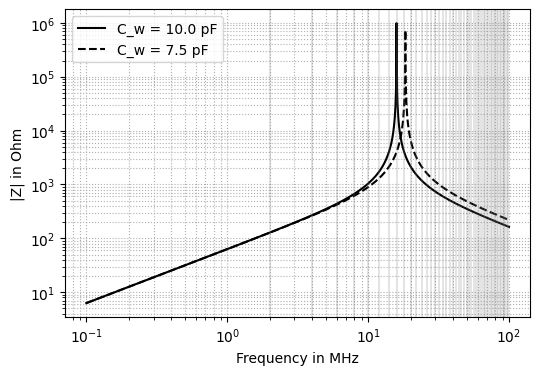

In [8]:
# Subtask 7.4.2 Impedance of the lumped model
if __name__ == "__main__":
    f = np.logspace(5, 8, 2000)
    w = 2 * np.pi * f
    plt.figure(figsize=(6, 4))
    for bf, ls in ((True, '-'), (False, '--')):
        Cw = get_Cw(C0, 2, bf)
        Z = 1 / (1 / (R_ac + 1j * w * L) + 1j * w * Cw)
        plt.loglog(f / 1e6, np.abs(Z), 'k' + ls, label=f"C_w = {Cw*1e12:.1f} pF")
    for k in range(1, 50):
        plt.axvline(2 * k, color='gray', lw=0.3)
    plt.xlabel('Frequency in MHz'); plt.ylabel('|Z| in Ohm')
    plt.grid(True, which='both', ls=':'); plt.legend(); plt.show()


### 7.4.2 Solution

Back and forth: $C_\mathrm{w} = C_0/3 = 10~\mathrm{pF}$, $f_\mathrm{SRF} = 15.9~\mathrm{MHz}$; same start side: $7.5~\mathrm{pF}$, $18.4~\mathrm{MHz}$. Above the self-resonance $|Z|$ falls with $1/f$: from about the 8th harmonic of the $2~\mathrm{MHz}$ converter on, the inductor no longer blocks the noise current.
